# Lab 05: Web Architecture and Protocols

*INFO 4617/5617 · Week 5 · Chapter 5, [Web Architecture and Protocols](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in.

We follow one page, the chapter's [University of Colorado Boulder](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder) article, down through the stack: what your browser's developer tools show, the addresses and DNS lookup under the request, the status codes and headers HTTP carries, and then a time series of the article's readers, from a URL we build ourselves. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

**Before class:** open this notebook in the `webdata` environment (chapter 1; it includes `dnspython`), have your email address ready for the User-Agent, and have Chrome, Firefox, or Safari open: Steps 1 and 2 happen in its developer tools. In Safari, first turn on **Settings → Advanced → Show features for web developers**.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell was run against the live sites on 2026-10-21 with `labs/tools/run_key.py`, from a cloud machine that reaches the web through a proxy, whose one public address other jobs were using too. The pageviews come from January 2026, the chapter's window, so Steps 6 and 7 will match a rerun; headers, cache ages, DNS answers, `Server` names, and timings change from run to run. Three of Step 3's outputs show that machine, not a laptop: its local address is 127.0.0.1, its public address is the proxy's, and curl's narration starts with a `CONNECT` to the proxy (and its `200 Connection Established`) before the TLS handshake. Not run: Step 3's optional `ping` cell (the machine has no `ping`, and its proxy carries only web traffic), and both cells of Step 7's microsprint, whose pageviews requests drew 429s on six runs over 12 minutes; with no error handling, the 429's HTML page fails at `.json()`, as Step 6's 💬 Discuss box asks. Step 10's Action API request and both `AC/DC` requests also drew 429s, which those cells print; a separate check the same evening got 404 for the raw `AC/DC` and 200 for `AC%2FDC`. Run Steps 7 and 10 again before class. The counts in Step 2's microsprint come from one page load of each page in headless Chromium, not from a person's browser. The lab follows the textbook at commit d9306b7.

## Step 0 — Set up (3 minutes)

Import [`requests`](https://requests.readthedocs.io/en/stable/user/quickstart/#custom-headers), `time`, `pandas`, and `matplotlib`, and define the [User-Agent](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/User-Agent) every request today will send, in the book's form, `WebDataScience/1.0 (your-email@colorado.edu)`, with your own address. Keep the chapter's article in `ARTICLE`, written as Wikipedia writes titles in URLs, with underscores, and its address in `PAGE`.

In [1]:
# Import requests, time, pandas (as pd), and matplotlib.pyplot (as plt)
# Define HEADERS: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Define ARTICLE, "University_of_Colorado_Boulder", and PAGE, its address on en.wikipedia.org; print HEADERS
import requests
import time
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
ARTICLE = "University_of_Colorado_Boulder"
PAGE = f"https://en.wikipedia.org/wiki/{ARTICLE}"
print(HEADERS)

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote this same User-Agent. Who reads it, and what can they do with your email address?
- Everyone in this room will send the same requests at about the same time. Which of week 2's five questions (legality, consent, proportionality, privacy, server impact) does that make pressing?

</details>

## Step 1 — The Inspector, then the same element in Python (6 minutes)

Open [the article](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder) in your browser, right-click its title, and choose **Inspect** (**Inspect Element** in Safari). The [Inspector](https://developer.chrome.com/docs/devtools/elements) (Chrome and Safari call it **Elements**) jumps to the title's node in the **DOM**, the browser's live tree of the page. Right-click that node and choose **Copy → Copy selector**. Then check in Python that the selector finds the same element in the HTML `requests` gets, with BeautifulSoup's [`select_one()`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#css-selectors). **Copy XPath** describes the same element in another language, which `select()` doesn't read: if there's time, paste it into a new cell as `soup.select('//*[@id="firstHeading"]')`, read the error's last line, and delete the cell, so that Friday's Run All doesn't stop there. For more, see the chapter's *Browser Developer Tools*, ["The Inspector Tab"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#the-inspector-tab).

In [2]:
# Paste the selector you copied into SELECTOR. Request PAGE with HEADERS, and print the status code
# Parse response.text with BeautifulSoup ("lxml"), and print the text of soup.select_one(SELECTOR)
from bs4 import BeautifulSoup

SELECTOR = "#firstHeading"
response = requests.get(PAGE, headers=HEADERS)
print(response.status_code)
soup = BeautifulSoup(response.text, "lxml")
print(soup.select_one(SELECTOR).text)

200
University of Colorado Boulder


<details>
<summary>💬 Discuss</summary>

- The Inspector shows the DOM; `requests` gets what View Source shows, as week 1's side-by-side figure did. If the title had been missing from `response.text`, what would that tell you?
- Why is an `id` like `firstHeading` a safer target for a scraper than a class name chosen for styling?
- In week 4 we found tags with `find()` and `find_all()`. When is a copied selector quicker, and when is it more brittle?

</details>

## Step 2 — The Network tab, and what one request carries (10 minutes)

Open the [Network tab](https://developer.chrome.com/docs/devtools/network) and reload the article: it records only while it's open. The status bar counts the requests; the first row is the HTML document, and the rest are what it asked for. Click that first row and read its **Headers**: the request headers your browser sent, and the response headers it got back. `requests` sends only the one request for the document, so compare it with that row. The **Size** column counts bytes on the wire, which are compressed: the [`Content-Encoding`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Content-Encoding) response header says how, and `Content-Length` says how many. `len(response.content)` counts them after `requests` has decompressed them. For more, see the chapter's ["The Network Tab"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#the-network-tab).

In [3]:
# Print the response's Content-Encoding and Content-Length headers, and len(response.content): which is closer to the Size column?
# Print two headers from Wikimedia's cache, x-cache and age (seconds the cached copy has been kept)
# Print response.request.headers, what requests sent. Compare it with your browser's request headers
for name in ["Content-Encoding", "Content-Length", "x-cache", "age"]:
    print(f"{name}: {response.headers.get(name)}")
print(f"len(response.content): {len(response.content):,} bytes")
print(response.request.headers)

Content-Encoding: gzip
Content-Length: 121505
x-cache: cp1108 miss, cp1108 hit/7
age: 1189
len(response.content): 768,062 bytes
{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive'}


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 1. Reload a news site you read with the Network tab open, and note the total number of requests and how many the **Doc**, **CSS**, **JS**, **Img**, **Fetch/XHR**, and **Font** filters each show (the rest are Other). Do the same for the article. Type the counts into the cell, and plot them side by side.
**Share:** the site, its total number of requests, and the share that are scripts (JS).

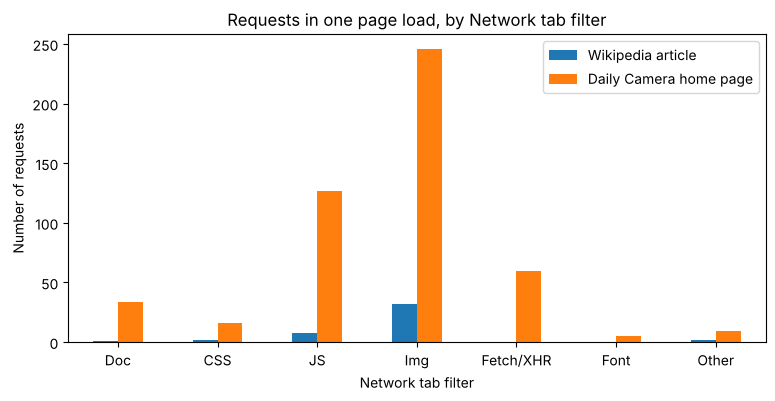

Wikipedia article          45
Daily Camera home page    497
dtype: int64
Wikipedia article         0.18
Daily Camera home page    0.26
dtype: float64


In [4]:
# Microsprint: put your counts in a dict of dicts, one per page: {"Wikipedia article": {"Doc": 1, "JS": 8, ...}, "<your site>": {...}}
# Make a DataFrame from it, and draw it as a bar chart on plt.subplots(), with a title and labeled axes
# Print each page's total number of requests, and the share of them that are JS
# The key's counts: one load of each page in headless Chromium on 2026-10-21, sorted into the Network tab's filters
counts = {
    "Wikipedia article": {"Doc": 1, "CSS": 2, "JS": 8, "Img": 32, "Fetch/XHR": 0, "Font": 0, "Other": 2},
    "Daily Camera home page": {"Doc": 34, "CSS": 16, "JS": 127, "Img": 246, "Fetch/XHR": 60, "Font": 5, "Other": 9},
}
by_type = pd.DataFrame(counts)
fig, ax = plt.subplots(figsize=(9, 4))
by_type.plot.bar(ax=ax, rot=0)
ax.set(title="Requests in one page load, by Network tab filter", xlabel="Network tab filter", ylabel="Number of requests")
plt.show()
print(by_type.sum())
print((by_type.loc["JS"] / by_type.sum()).round(2))

<details>
<summary>💬 Discuss</summary>

- Your browser made dozens of requests for the article; `requests` made one. What does a scraper never see, and what does it spare the server?
- In week 3 we read the `server` and `via` headers to learn who refused us. What does Wikimedia's `x-cache` header let you say about who answered?
- A news home page can load hundreds of requests from dozens of hosts. Who learns that you visited it?

</details>

## Step 3 — Below HTTP: addresses, and one connection narrated (7 minutes)

HTTP rides on TCP/IP: every machine has an IP address, and a request travels as packets between two of them. [`socket`](https://docs.python.org/3/library/socket.html) asks your operating system for your machine's name and local address; a service like [ipify](https://www.ipify.org/) reports the public address servers see. Mask its last two numbers before you print it, as the chapter does, because notebooks end up on screens and in repositories.

Then let `curl` narrate one request. A line that starts with `!` runs in your terminal, and [`lines = !command`](https://ipython.readthedocs.io/en/stable/interactive/python-ipython-diff.html#shell-assignment) keeps its output as a list. `curl -v` narrates on its error stream, so add `2>&1` to keep it, and print only the lines for the connection (`* Connected`), the TLS handshake's result (`* SSL connection`), the request (`>`), and the response's status line (`< HTTP`). For more, see the chapter's *TCP/IP: The Transport Layer* and "Packets".

If there's time, the optional cell after them pings Wikipedia: four small packets out, four replies back. Campus Wi-Fi may drop them.

In [5]:
# Import socket. Print your hostname, and the address socket.gethostbyname() gives for it
# Get your public IP from https://api.ipify.org?format=json, and print it with its last two numbers replaced by xxx
import socket

hostname = socket.gethostname()
print(f"Hostname: {hostname}; local IP: {socket.gethostbyname(hostname)}")
public_ip = requests.get("https://api.ipify.org?format=json", headers=HEADERS).json()["ip"]
print(f"Public IP: {'.'.join(public_ip.split('.')[:2])}.xxx.xxx")

Hostname: vm; local IP: 127.0.0.1


Public IP: 160.79.xxx.xxx


In [6]:
# Run lines = !curl -v -I -A "<your User-Agent>" https://en.wikipedia.org/wiki/Web_scraping 2>&1, and print the lines
#   that start with "* Connected", "* SSL connection", ">", or "< HTTP"
lines = !curl -v -I -A "WebDataScience/1.0 (your-email@colorado.edu)" https://en.wikipedia.org/wiki/Web_scraping 2>&1
for line in lines:
    if line.startswith(("* Connected", "* SSL connection", ">", "< HTTP")):
        print(line)

* Connected to 127.0.0.1 (127.0.0.1) port 34513
> CONNECT en.wikipedia.org:443 HTTP/1.1
> Host: en.wikipedia.org:443
> User-Agent: WebDataScience/1.0 (your-email@colorado.edu)
> Proxy-Connection: Keep-Alive
> 
* SSL connection using TLSv1.3 / TLS_AES_128_GCM_SHA256 / X25519 / id-ecPublicKey
> HEAD /wiki/Web_scraping HTTP/2
> Host: en.wikipedia.org
> User-Agent: WebDataScience/1.0 (your-email@colorado.edu)
> Accept: */*
> 
< HTTP/2 200 


In [ ]:
# Optional: ping Wikipedia four times (on Windows, write -n 4 instead of -c 4)
!ping -c 4 en.wikipedia.org

<details>
<summary>💬 Discuss</summary>

- `socket.gethostbyname()` may give you 127.0.0.1, which means "this machine". Why is the public address the one a server's logs record?
- curl reports the connection done before it sends a byte of HTTP. Which layer did that work, and why doesn't curl show its three packets?
- Week 1 asked us to treat `requests` as a well-made black box. Which parts of what curl narrated does `requests` do for you without a word?

</details>

## Step 4 — DNS: from a name to an address (8 minutes)

Before any of that, the name had to become an address. [`dns.resolver.resolve()`](https://dnspython.readthedocs.io/en/stable/resolver-functions.html#dns.resolver.resolve) asks a DNS server for a name's **A** records, its IPv4 addresses. The answer holds more than the address: [`canonical_name`](https://dnspython.readthedocs.io/en/stable/resolver-class.html#dns.resolver.Answer.canonical_name) is the name the record belongs to, when the name you asked for is an alias, and `rrset.ttl` is how many seconds resolvers may cache the answer. `socket.gethostbyname()`, the lookup `requests` relies on, should agree. If `dns.resolver` raises `NoNameservers ... answered REFUSED`, see the chapter's *Common Issues to Debug*. For more, see the chapter's [*DNS: The Address Book*](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#dns-the-address-book).

In [7]:
# Import dns.resolver. Resolve en.wikipedia.org's A record, and print each address in the answer
# Print the answer's canonical_name and rrset.ttl, and what socket.gethostbyname("en.wikipedia.org") says
# Keep the first address, as a string, in WIKI_IP
import dns.resolver

answers = dns.resolver.resolve("en.wikipedia.org", "A")
for answer in answers:
    print(f"IP address: {answer}")
print(f"Canonical name: {answers.canonical_name}")
print(f"TTL: {answers.rrset.ttl} seconds")
print(f"socket says: {socket.gethostbyname('en.wikipedia.org')}")
WIKI_IP = str(answers[0])

IP address: 208.80.154.224
Canonical name: dyna.wikimedia.org.
TTL: 180 seconds
socket says: 208.80.154.224


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** find where that address is. Send the request inside the chapter's `geolocate_ip()`, from its traceroute section, which asks [ip-api](https://ip-api.com/docs/api:json) about an address, for `WIKI_IP`. Then print Step 1's `Server` header: Wikimedia names its servers after their data centers, and `eqiad` is Ashburn, Virginia; `codfw` is Carrollton, Texas.
**Share:** your address, the city ip-api gives it, and the data center in your `Server` header.

In [8]:
# Microsprint: request http://ip-api.com/json/{WIKI_IP} with HEADERS, as the chapter's geolocate_ip() does, and keep the JSON
# Print its city, regionName, and isp. Then print response.headers["Server"] from Step 1
# (ip-api allows 45 requests a minute from one address, and this room shares one)
location = requests.get(f"http://ip-api.com/json/{WIKI_IP}", headers=HEADERS).json()
print(f"{WIKI_IP}: {location['city']}, {location['regionName']} | {location['isp']}")
print(response.headers["Server"])

208.80.154.224: San Francisco, California | Wikimedia Foundation Inc.
mw-web.eqiad.main-855b9df8d-8fd9x


<details>
<summary>💬 Discuss</summary>

- In the key, ip-api put Wikipedia's address in San Francisco, where the Wikimedia Foundation has its office, while the `Server` header named a data center in Virginia or Texas. What does an IP geolocation service look up, and which answer do you believe?
- Did everyone in the room get the same address? Why might someone on a phone hotspot get a different one?
- Resolvers may keep this answer for `ttl` seconds. If Wikipedia moved its servers tomorrow, how long could some of us still be sent to the old address?

</details>

## Step 5 — Status codes, read plainly (9 minutes)

HTTP is the layer you talk to. A response's [status code](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status) is the server's verdict: 200 OK; 301 or 302, moved (the `Location` header says where); 403, refused; 404, not found; 429, slow down; 500, the server's own failure. Request the article and a page that doesn't exist, and print what the chapter's `diagnose_request()` prints: the status, `Content-Type`, `Server`, and size. We write its lines straight, without the function or its `try`/`except`. Then request the article again without `HEADERS`, to check the chapter's claim that Wikipedia answers an unnamed client with a [403](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status/403), and read that 403's body. For more, see the chapter's ["Diagnosing HTTP Errors"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#diagnosing-http-errors).

In [9]:
# Request PAGE and .../wiki/Nonexistent_Page_12345 with HEADERS, a second apart; for each, print
#   the status code, Content-Type, Server, and size in bytes (len(response.content))
# Then request PAGE with no headers, and print its status code, Server, and the body's first 120 characters
missing = "https://en.wikipedia.org/wiki/Nonexistent_Page_12345"
for url in [PAGE, missing]:
    response = requests.get(url, headers=HEADERS)
    print(f"{response.status_code} | {response.headers['Content-Type']} | {response.headers['Server']} | {len(response.content):,} bytes")
    time.sleep(1)
anonymous = requests.get(PAGE)
print(f"{anonymous.status_code} | {anonymous.headers['Server']} | {anonymous.text[:120]}")

200 | text/html; charset=UTF-8 | mw-web.eqiad.main-855b9df8d-fzg98 | 768,062 bytes


404 | text/html; charset=UTF-8 | mw-web.eqiad.main-855b9df8d-zv4lx | 50,827 bytes


403 | HAProxy | Please set a user-agent and respect our robot policy https://w.wiki/4wJS. See also https://phabricator.wikimedia.org/T40


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** follow redirects by hand. Request `https://en.wikipedia.org/` and `https://en.wikipedia.org/wiki/CU_Boulder` with [`allow_redirects=False`](https://requests.readthedocs.io/en/stable/user/quickstart/#redirection-and-history), and print each one's status code and `Location` header. Then request `CU_Boulder` normally, and print its `response.history` and the title in its `#firstHeading`.
**Share:** the two status codes, and the page each address ended up on.

In [10]:
# Microsprint: request each of the two URLs with HEADERS and allow_redirects=False, a second apart; print its status code and Location header
# Then request the CU_Boulder URL normally: print its .url, its .history, and the text of its #firstHeading
for url in ["https://en.wikipedia.org/", "https://en.wikipedia.org/wiki/CU_Boulder"]:
    hop = requests.get(url, headers=HEADERS, allow_redirects=False)
    print(f"{url}: {hop.status_code}, Location: {hop.headers.get('Location')}")
    time.sleep(1)
alias = requests.get("https://en.wikipedia.org/wiki/CU_Boulder", headers=HEADERS)
print(alias.url, alias.history)
print(BeautifulSoup(alias.text, "lxml").select_one("#firstHeading").text)

https://en.wikipedia.org/: 301, Location: https://en.wikipedia.org/wiki/Main_Page


https://en.wikipedia.org/wiki/CU_Boulder: 200, Location: None


https://en.wikipedia.org/wiki/CU_Boulder []
University of Colorado Boulder


<details>
<summary>💬 Discuss</summary>

- The 403 came with a `Server` header and a body. In week 3 we read both before blaming a platform for a refusal. Who refused us here, and how do you know?
- `CU_Boulder` answered 200 but showed another article's title. What would a check of the status code alone have missed?
- A 404 page is still a page, with a size and a Content-Type. Why did week 2's `responsible_get()` call `raise_for_status()` instead of checking whether text came back?

</details>

## Step 6 — Ask the pageviews API, politely (6 minutes)

Now an API. The [Wikimedia pageviews API](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html) puts every parameter in the URL's path: project, access, agent, article, granularity, start, and end. Keep the part that stays the same in `PAGEVIEWS`, and add the article and dates with an f-string. Without a User-Agent that names you, the API answers 403. When many clients share one address, as this room does, it may answer 429, with a [`Retry-After`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Retry-After) header saying how many seconds to wait; the chapter's `get_with_backoff()` waits that long and tries again. We don't write it: today's code assumes each request works, and the 💬 Discuss box asks what would break. Use January 2026, the chapter's window, so your numbers match the key's. For more, see the chapter's ["Making API Requests with Custom Headers"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#making-api-requests-with-custom-headers).

In [11]:
# Define PAGEVIEWS: the per-article pageviews URL for en.wikipedia, all-access, all-agents, up to the article
# Build api_url from PAGEVIEWS, ARTICLE, daily, 20260101, and 20260131. Request it with no headers, and print the status; wait a second
# Request it again with HEADERS, print the status, keep .json() as data, and print the number of days and the first day
PAGEVIEWS = "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/en.wikipedia/all-access/all-agents"
api_url = f"{PAGEVIEWS}/{ARTICLE}/daily/20260101/20260131"
print(requests.get(api_url).status_code)
time.sleep(1)
response = requests.get(api_url, headers=HEADERS)
print(response.status_code)
data = response.json()
print(len(data["items"]), "days; the first:", data["items"][0])

403


200
31 days; the first: {'project': 'en.wikipedia', 'article': 'University_of_Colorado_Boulder', 'granularity': 'daily', 'timestamp': '2026010100', 'access': 'all-access', 'agent': 'all-agents', 'views': 657}


<details>
<summary>💬 Discuss</summary>

- In week 1 we called this same API and got data back the first time. What did that request already carry that today's first one lacked?
- Our code assumes the second request works. If this room's shared address drew a 429 instead, which line would fail, and with what error? How would the chapter's `get_with_backoff()` have guarded against it?
- Why put a fixed date range in the URL rather than asking for "the last 30 days"?

</details>

## Step 7 — From JSON to a time series (9 minutes)

The views sit under `data["items"]`, one dictionary per day: week 4's list-of-dictionaries pattern, which `pd.DataFrame()` turns into a table in one call. Turn `timestamp`, written year, month, day, and hour (`2026010100`), into dates with [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) and `format="%Y%m%d00"`. Plot views by date on [`plt.subplots()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), with a title and labeled axes, and find the biggest day with `idxmax()`. For more, see the end of the chapter's ["Making API Requests with Custom Headers"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#making-api-requests-with-custom-headers).

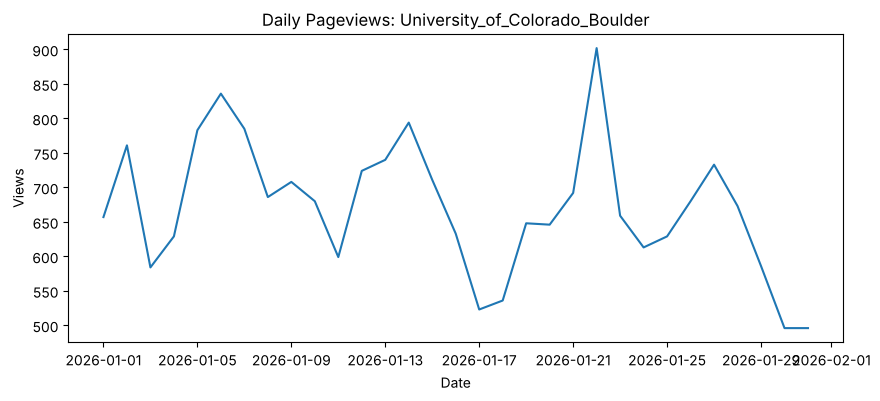

2026-01-22: 902 views


In [12]:
# Make a DataFrame from data["items"], and turn its timestamp into dates (format="%Y%m%d00")
# Plot views by date on plt.subplots(), with a title and labeled axes
# Print the day with the most views, and how many
df = pd.DataFrame(data["items"])
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y%m%d00")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["timestamp"], df["views"])
ax.set(title=f"Daily Pageviews: {ARTICLE}", xlabel="Date", ylabel="Views")
plt.show()
peak = df.loc[df["views"].idxmax()]
print(f"{peak['timestamp'].date()}: {peak['views']:,} views")

### ⏱ Microsprint (6 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 3. Get the same month's daily views for our article and two related ones (another university, the city, a team), in one table with a column for each, and plot all three on one set of axes.
**Share:** your two articles, which of the three had the biggest spike, on what day, and a guess at why.

In [ ]:
# Microsprint: for ARTICLE and two related articles, a second apart, request the same month's views with HEADERS
#   and keep each one's views, indexed by timestamp, in a dict; make a DataFrame from it, and turn its index into dates
series = {}
for title in [ARTICLE, "Colorado_State_University", "University_of_Denver"]:
    items = requests.get(f"{PAGEVIEWS}/{title}/daily/20260101/20260131", headers=HEADERS).json()["items"]
    series[title] = pd.DataFrame(items).set_index("timestamp")["views"]
    time.sleep(1)
compare = pd.DataFrame(series)
compare.index = pd.to_datetime(compare.index, format="%Y%m%d00")

In [ ]:
# Microsprint: plot compare on plt.subplots(), with a title and labeled axes (pandas adds the legend)
# Print each article's biggest day and its views
fig, ax = plt.subplots(figsize=(10, 4))
compare.plot(ax=ax)
ax.set(title="Daily pageviews, January 2026", xlabel="Date", ylabel="Views")
plt.show()
print(pd.DataFrame({"biggest day": compare.idxmax().dt.date, "views": compare.max()}))

<details>
<summary>💬 Discuss</summary>

- What happened on the biggest day? How would you check it, rather than guess?
- These are `all-agents` counts, crawlers included. Which claims about attention can this plot support, and which can't it?
- Week 1 plotted this article's same January. Should your numbers match the ones you got then, and why?

</details>

## Step 8 — What a server sees: honest and spoofed User-Agents (4 minutes)

A [`User-Agent`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/User-Agent) is whatever the client says it is. [httpbin.org](https://httpbin.org/)'s `/user-agent` endpoint echoes back the header it received, so you can see exactly what a server gets: `requests`' default, your honest identification, and a **spoofed** one that claims to be desktop Chrome. Spoofing is the same dictionary with a false value. The chapter's callout explains why this course doesn't use it to get past a block. For more, see the chapter's ["User-Agent Spoofing"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#user-agent-spoofing).

In [15]:
# Define spoofed_headers, whose User-Agent claims to be Chrome on Windows (copy the chapter's string)
# Ask https://httpbin.org/user-agent three times, a second apart, and print the JSON: with no headers, with HEADERS, and with spoofed_headers
spoofed_headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36"
    )
}
for headers in [None, HEADERS, spoofed_headers]:
    print(requests.get("https://httpbin.org/user-agent", headers=headers).json())
    time.sleep(1)

{'user-agent': 'python-requests/2.34.2'}


{'user-agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}


{'user-agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36'}


<details>
<summary>💬 Discuss</summary>

- By this header alone, the server can't tell the spoofed request from Chrome. What else could it check? Step 2's comparison of request headers is a hint.
- Week 2 asked whether a collection is consistent with a site's terms. When is changing your User-Agent unremarkable, and when does it become getting around a block?

</details>

## Step 9 — A Session that reuses its connection (7 minutes)

Each bare `requests.get()` opens a connection, does the TLS handshake Step 3 narrated, and closes it. A [`requests.Session`](https://requests.readthedocs.io/en/stable/user/advanced/#session-objects) keeps the connection open for the next request to the same host, and remembers your headers. The chapter also mounts a [`Retry`](https://urllib3.readthedocs.io/en/stable/reference/urllib3.util.html#urllib3.util.Retry) rule on its session, which retries 429s and server errors and honors `Retry-After`, as `get_with_backoff()` does by hand. We leave it out, like every retry today, and talk about it instead. For more, see the chapter's ["Connections, Sessions, and Retries"](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#connections-sessions-and-retries).

In [16]:
# Make a Session, and put HEADERS in session.headers
# Loop over the chapter's three articles, a second apart: get each with the session, and print its title, status, and length
session = requests.Session()
session.headers.update(HEADERS)
articles = ["Python_(programming_language)", "Web_scraping", "Data_science"]
for article in articles:
    response = session.get(f"https://en.wikipedia.org/wiki/{article}")
    print(f"{article}: {response.status_code}, {len(response.text):,} characters")
    time.sleep(1)

Python_(programming_language): 200, 1,012,849 characters


Web_scraping: 200, 235,984 characters


Data_science: 200, 283,349 characters


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check the chapter's claim that a Session saves work. For each of the three articles, make one bare `requests.get()` and one `session.get()`, and compare their [`response.elapsed`](https://requests.readthedocs.io/en/stable/api/#requests.Response.elapsed), the time from sending the request until its response's headers arrived.
**Share:** the two times for one article, and how much the Session saved.

In [17]:
# Microsprint: for each article, a second apart, make one bare requests.get() (with HEADERS) and one session.get()
# Print each response's elapsed time in seconds (.elapsed.total_seconds())
for article in articles:
    bare = requests.get(f"https://en.wikipedia.org/wiki/{article}", headers=HEADERS)
    reused = session.get(f"https://en.wikipedia.org/wiki/{article}")
    print(f"{article}: bare {bare.elapsed.total_seconds():.2f} s, session {reused.elapsed.total_seconds():.2f} s")
    time.sleep(1)

Python_(programming_language): bare 0.39 s, session 0.06 s


Web_scraping: bare 0.36 s, session 0.06 s


Data_science: bare 0.36 s, session 0.07 s


<details>
<summary>💬 Discuss</summary>

- Is this a fair race? The session's connection was already open from the loop above. What would make the comparison fairer?
- The chapter's `Retry` rule would have retried a 429 or a 503 for us, quietly. What would it hide from you that today's plain code shows?
- Week 2 asked for a pause between requests. Does a Session make a loop polite on its own?

</details>

## Step 10 — Take a URL apart, and build one safely (9 minutes)

Don't parse URLs with regular expressions: [`urllib.parse`](https://docs.python.org/3/library/urllib.parse.html) knows their grammar, `scheme://host:port/path?query#fragment`. `urlparse()` splits a URL into its parts, and `parse_qs()` turns its query into a dictionary. Building goes the other way, in two patterns. A **path-segment** API, like pageviews, needs each value made safe for its slot with [`quote(value, safe="")`](https://docs.python.org/3/library/urllib.parse.html#urllib.parse.quote). A **query-parameter** API, like the MediaWiki Action API, takes a dictionary, which `urlencode()` escapes, or which `requests` escapes for you when you pass it as `params=`. For more, see the chapter's [*URLs: Anatomy and Parsing*](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html#urls-anatomy-and-parsing).

In [18]:
# From urllib.parse import urlparse, parse_qs, quote, and urlencode
# urlparse() the chapter's Census URL: print its scheme, netloc (host), and path, and parse_qs() of its query
from urllib.parse import urlparse, parse_qs, quote, urlencode

parsed = urlparse("https://api.census.gov/data/2022/acs/acs5?get=NAME,B01001_001E&for=place:07850&in=state:08")
print(f"Scheme: {parsed.scheme}, host: {parsed.netloc}, path: {parsed.path}")
print(parse_qs(parsed.query))

Scheme: https, host: api.census.gov, path: /data/2022/acs/acs5
{'get': ['NAME,B01001_001E'], 'for': ['place:07850'], 'in': ['state:08']}


In [19]:
# quote() "University of Colorado Boulder" for a path segment: spaces to underscores first, and safe=""
# urlencode() the chapter's Action API params (action=query, format=json, titles, prop=info), and print the result
# Then session.get() the Action API with params=params, and print response.url and the status code
print(quote("University of Colorado Boulder".replace(" ", "_"), safe=""))
params = {"action": "query", "format": "json", "titles": "University of Colorado Boulder", "prop": "info"}
print(urlencode(params))
response = session.get("https://en.wikipedia.org/w/api.php", params=params)
print(response.url)
print(response.status_code)

University_of_Colorado_Boulder
action=query&format=json&titles=University+of+Colorado+Boulder&prop=info
https://en.wikipedia.org/w/api.php?action=query&format=json&titles=University+of+Colorado+Boulder&prop=info
429


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check the chapter's warning about slashes. Build January 2026's pageviews URL for the article `AC/DC` twice: once with the raw title in the f-string, once with `quote(title, safe="")`. Request both with your session.
**Share:** the two status codes, and what the server took the raw slash to mean.

In [20]:
# Microsprint: for the title "AC/DC", build January 2026's daily pageviews URL from PAGEVIEWS twice: with the raw title,
#   and with quote(title, safe=""). Request both with session.get(), a second apart, and print each segment and its status code
title = "AC/DC"
for segment in [title, quote(title, safe="")]:
    reply = session.get(f"{PAGEVIEWS}/{segment}/daily/20260101/20260131")
    print(f"{segment}: {reply.status_code}")
    time.sleep(1)

AC/DC: 429


AC%2FDC: 429


<details>
<summary>💬 Discuss</summary>

- `quote("AC/DC")` without `safe=""` leaves the slash alone. Why is that the default, and why is it wrong for a path segment?
- Look at the Action API's `response.url`. Which characters did `requests` escape, and how?
- Week 3's access matrix probed APIs of both kinds. How can you tell from a URL alone which kind you have? Name one of each from that list.

</details>

## Step 11 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- In Step 2 and its microsprint, how many requests did your browser make for the article, and for the news site? What does a scraper that sends one request never see?
- Which of today's outputs (Steps 3 and 4 above all) describe your own network or machine rather than Wikipedia?
- Which status codes did we meet in Steps 5 and 6, and which response would a check of the status code alone have read wrongly?
- Why did the raw `AC/DC` URL in Step 10's microsprint fail, and what told you?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, take a URL apart: Step 10's `urlparse()` of the Census URL.
- Step 2, resolve a name: Step 4's `dns.resolver.resolve()`.
- Step 3, request with named headers: Step 0's `HEADERS`, and Step 2's reading of response headers (and why `Content-Length` and `len(response.content)` differ).
- Step 4, write `diagnose_url()`: Step 5's lines that read the status, `Content-Type`, `Server`, and size, and its microsprint's redirects (`Location`, `response.history`). The exercise gathers them into a function, and adds the `timeout=` that today's code left out.
- Step 5, profile five URLs: Steps 5 and 6 (a page, a 404, a refusal, an API), and week 3's habit of reading a refusal's `Server` header and body.
- Step 6, interpret: Step 2's compressed and decompressed sizes, Step 5's `Content-Type` and `Server` headers, and week 3's question of who answered.

In [21]:
# Your answers here, as comments
# Step 2: the key's page loads made 45 requests for the article and 497 for the Daily Camera's home page
#   (26% of them scripts, against 18% for the article); requests made 1, and got 768,062 bytes of HTML,
#   sent as 121,505 gzipped bytes. A scraper never sees the scripts, images, and Fetch/XHR data the browser loads.
# Our network, not Wikipedia: the local IP 127.0.0.1, the public IP (the proxy's, in the key), curl's CONNECT
#   to the proxy, and the DNS answer (208.80.154.224, cacheable for 180 s), which depends on where you ask from.
#   ip-api's "San Francisco" describes who registered the address, not where the eqiad server is.
# We met 200, 301 (en.wikipedia.org/ to Main_Page), 403 twice (HAProxy's "Please set a user-agent" for the
#   article, and the pageviews API's for our unnamed request), 404 (a 50,827-byte page), and 429s from the
#   shared address in Step 10. CU_Boulder answered 200, with no redirect in its history, under another article's
#   title: a status-only check would read it as the page we asked for.
# The raw "AC/DC" puts a slash in the path, so the API reads two segments. In the key both requests drew 429s,
#   so the status said nothing about the slash; a check the same evening got 404 for the raw title and 200 for
#   AC%2FDC. Only the status code told us: nothing else warns you.

## Friday: from the lab to the textbook (15 minutes)

Did anything in this lab disagree with chapter 5? Places to look:

- **Step 4's microsprint.** The chapter maps traceroute hops with `geolocate_ip()`, but ip-api placed Wikipedia's address in San Francisco, at the Foundation's office, while the `Server` header named a data center in Virginia or Texas. Should the chapter say what an IP geolocation service looks up?
- **The helpers.** We wrote the lines inside the chapter's `diagnose_request()` and `geolocate_ip()` straight, and left `get_with_backoff()` and the Session's `Retry` rule to discussion. Did the plain version read more easily, and what did it give up? (The chapter's `geolocate_ip()` also sends no User-Agent, though chapter 2 asks for one.)
- **Outputs that have moved.** The chapter's Network tab figure counts 37 requests for the article, and its `Session` example prints page lengths from when it was written. What did you get?
- **A cell that broke for you,** such as `ping` on campus Wi-Fi, or `dns.resolver` off campus. Is the chapter's *Common Issues to Debug* enough?
- **A microsprint that would make a good exercise,** such as Step 10's `AC/DC` check.

[`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) says how to propose a revision.